In [1]:
import torch
from torch import nn

# nn.Embedding(num_embedding, embedding_dim)
# num_embedding: vocab_size
# embedding_dim: channels, C
embedding = nn.Embedding(num_embeddings=3, embedding_dim=2)

print(embedding.weight)  # The whole table: 3 rows, 2 numbers per row

ids = torch.tensor([2, 0, 2])
print(embedding(ids))    # Returns rows 2, 0, and 2 from that table

Parameter containing:
tensor([[ 0.2543,  0.0325],
        [ 1.1689,  1.5927],
        [-0.0992,  1.1292]], requires_grad=True)
tensor([[-0.0992,  1.1292],
        [ 0.2543,  0.0325],
        [-0.0992,  1.1292]], grad_fn=<EmbeddingBackward0>)


In [4]:
# ids: 4*5, batch_size*block_size
# batch_size: B
# block_size: context_length, time, T
ids = torch.tensor([[2, 0, 2, 1, 0],
                    [1, 1, 0, 1, 1],
                    [0, 2, 2, 2, 0],
                    [2, 0, 1, 1, 2]])
print(embedding(ids))    
# output: 4*5*2, batch_size*block_size*embedding_dim

tensor([[[-1.4238, -0.6879],
         [-0.6569,  0.4552],
         [-1.4238, -0.6879],
         [ 0.9706,  0.0748],
         [-0.6569,  0.4552]],

        [[ 0.9706,  0.0748],
         [ 0.9706,  0.0748],
         [-0.6569,  0.4552],
         [ 0.9706,  0.0748],
         [ 0.9706,  0.0748]],

        [[-0.6569,  0.4552],
         [-1.4238, -0.6879],
         [-1.4238, -0.6879],
         [-1.4238, -0.6879],
         [-0.6569,  0.4552]],

        [[-1.4238, -0.6879],
         [-0.6569,  0.4552],
         [ 0.9706,  0.0748],
         [ 0.9706,  0.0748],
         [-1.4238, -0.6879]]], grad_fn=<EmbeddingBackward0>)


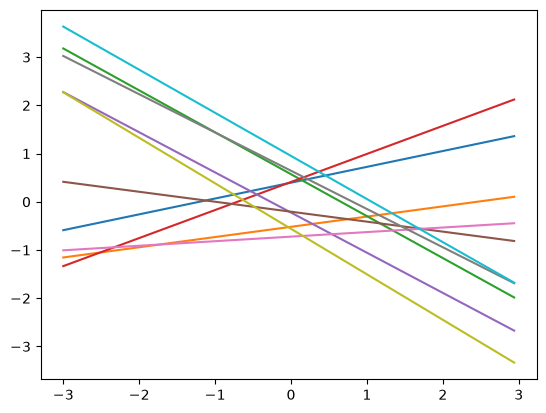

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# continuous embedding
test_layer = nn.Linear(1, 10)
a = torch.arange(-3,3,0.06).unsqueeze(-1)
# print(a.view(100))

for i in range(10):
    plt.plot(a.view(100).detach().numpy(), test_layer(a)[:, i].detach().numpy())
plt.show()